In [ ]:
#Mount Google Drive To Load Dataset

from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
#Obtain the number of test and train image and mask files

import os
import cv2
import numpy as np

IMG_HEIGHT, IMG_WIDTH = 256, 256

base_dir = "/content/drive/MyDrive/Brain_Tumor_Segmentation/segmentation_task"

train_images_path = os.path.join(base_dir, "train", "image")
train_masks_path  = os.path.join(base_dir, "train", "mask")
test_images_path  = os.path.join(base_dir, "test", "image")
test_masks_path   = os.path.join(base_dir, "test", "mask")

print("Train image:", len(os.listdir(train_images_path)))
print("Train mask :", len(os.listdir(train_masks_path)))
print("Test image :", len(os.listdir(test_images_path)))
print("Test mask  :", len(os.listdir(test_masks_path)))


Train image: 3933
Train mask : 3933
Test image : 860
Test mask  : 860


In [ ]:
#Build the dataset x_train, y_train, x_test, y_test
#Dataset loader to handle the previous test image and mask correctly

import os
import cv2
import numpy as np

def load_dataset(image_path, mask_path, img_height=256, img_width=256):
    # only keep image files
    def valid_files(path):
        return sorted([
            f for f in os.listdir(path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    image_files = valid_files(image_path)
    mask_files  = valid_files(mask_path)

    X, Y = [], []

    # pair by index (assumes same ordering)
    for img_name, mask_name in zip(image_files, mask_files):
        img_file  = os.path.join(image_path, img_name)
        mask_file = os.path.join(mask_path, mask_name)

        img  = cv2.imread(img_file,  cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(mask_file, cv2.IMREAD_GRAYSCALE)

        # if either failed to load, skip and warn
        if img is None:
            print("Warning: could not read image:", img_file)
            continue
        if mask is None:
            print("Warning: could not read mask :", mask_file)
            continue

        img  = cv2.resize(img,  (img_width, img_height))
        mask = cv2.resize(mask, (img_width, img_height),
                          interpolation=cv2.INTER_NEAREST)

        img  = img.astype(np.float32) / 255.0
        mask = (mask > 0).astype(np.uint8)

        X.append(img)
        Y.append(mask)

    X = np.array(X)
    Y = np.array(Y)
    print(f"Loaded {len(X)} image–mask pairs from {image_path}")
    return X, Y

In [ ]:
#load datasets
X_train, Y_train = load_dataset(train_images_path, train_masks_path)
X_test,  Y_test  = load_dataset(test_images_path,  test_masks_path)

print("X_train:", X_train.shape)
print("Y_train:", Y_train.shape)
print("X_test :", X_test.shape)
print("Y_test :", Y_test.shape)


Loaded 3933 image–mask pairs from /content/drive/MyDrive/Brain_Tumor_Segmentation/segmentation_task/train/image
Loaded 860 image–mask pairs from /content/drive/MyDrive/Brain_Tumor_Segmentation/segmentation_task/test/image
X_train: (3933, 256, 256)
Y_train: (3933, 256, 256)
X_test : (860, 256, 256)
Y_test : (860, 256, 256)


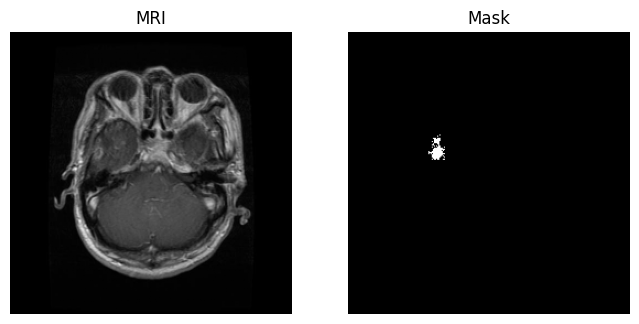

In [ ]:
#Goal is to visualize one image and one mask

import matplotlib.pyplot as plt

idx = 10   # you can change this index

img  = X_train[idx]
mask = Y_train[idx]

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(img,  cmap="gray"); plt.title("MRI");  plt.axis("off")
plt.subplot(1,2,2); plt.imshow(mask, cmap="gray"); plt.title("Mask"); plt.axis("off")
plt.show()


In [ ]:
#First Pipeline
#Apply Gaussian Filter
#Apply Thresholding
#Disk Opening and Closing

import numpy as np
from scipy.ndimage import gaussian_filter
from skimage.filters import threshold_multiotsu
from skimage.morphology import disk, opening, closing

def classical_brain_segmentation(image_2d,
                                 gauss_sigma=0.8,
                                 morph_radius=2):
    """
    Segment brain MRI into 3 classes using classical methods
    Returns: label map (0=background, 1=CSF, 2=Gray matter, 3=White matter)
    """
    # 1) Smoothing (less aggressive for brain MRI)
    smoothed = gaussian_filter(image_2d, sigma=gauss_sigma)

    # 2) Multi-Otsu for 3 tissue classes + background
    thresholds = threshold_multiotsu(smoothed, classes=4)

    # 3) Create regions
    regions = np.digitize(smoothed, bins=thresholds)

    # 4) Clean up each tissue class separately
    selem = disk(morph_radius)
    cleaned = np.zeros_like(regions)

    for label in range(1, 4):  # Skip background (0)
        tissue_mask = (regions == label)
        # Opening to remove small noise
        tissue_clean = opening(tissue_mask, selem)
        # Closing to fill small holes
        tissue_clean = closing(tissue_clean, selem)
        cleaned[tissue_clean] = label

    return cleaned

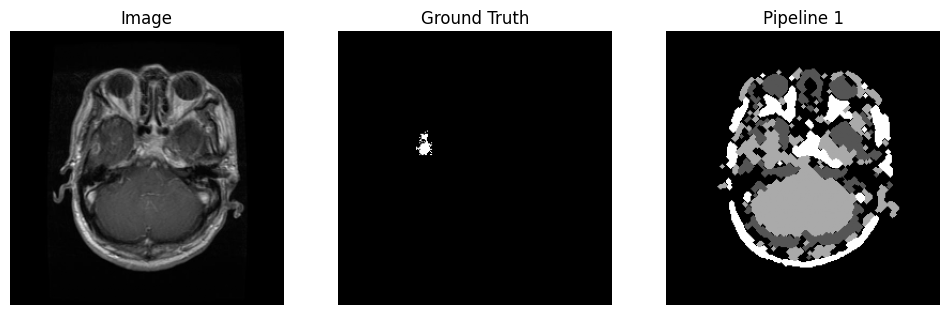

In [ ]:
#Try the first pipeline on one training image

idx = 10  # same index as before or a new one

img  = X_train[idx]
gt   = Y_train[idx]
pred = classical_brain_segmentation(img)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img, cmap="gray");  plt.title("Image");        plt.axis("off")
plt.subplot(1,3,2); plt.imshow(gt,  cmap="gray");  plt.title("Ground Truth"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(pred, cmap="gray"); plt.title("Pipeline 1");   plt.axis("off")
plt.show()

In [ ]:
#Add dice score to measure the quality

import numpy as np

def dice_score(y_true, y_pred):
    y_true = y_true.astype(bool)
    y_pred = y_pred.astype(bool)

    intersection = np.logical_and(y_true, y_pred).sum()
    return 2 * intersection / (y_true.sum() + y_pred.sum() + 1e-8)

score = dice_score(gt, pred)
print("Dice score for image", idx, ":", score)

Dice score for image 10 : 0.014126021912010385


In [ ]:
#Test on the first 50 test images to see the results

n_samples = min(50, len(X_test))
dice_scores = []

for i in range(n_samples):
    img  = X_test[i]
    gt   = Y_test[i]
    pred = classical_brain_segmentation(img)

    d = dice_score(gt, pred)
    dice_scores.append(d)

print("Average Dice over", n_samples, "test images:", np.mean(dice_scores))
print("Min Dice:", np.min(dice_scores), " Max Dice:", np.max(dice_scores))

Average Dice over 50 test images: 0.11304985912815763
Min Dice: 0.01083521444694648  Max Dice: 0.29639782882817234


In [ ]:
#Pipeline 2 (Kmeans + Fuzzy C Means)

from sklearn.cluster import KMeans
from skimage.morphology import opening, closing, disk
import numpy as np # Ensure numpy is imported for array operations

def kmeans_segmentation(image,
                        n_clusters=3,
                        morph_radius=3):
    h, w = image.shape
    X_flat = image.reshape(-1, 1)

    kmeans = KMeans(n_clusters=n_clusters,
                    random_state=0,
                    n_init=10)
    labels = kmeans.fit_predict(X_flat)

    labels_img = labels.reshape(h, w)

    # Choose tumor-intensity cluster, threshold to binary, then morphology...
    # Find the intensity values of the cluster centers
    # kmeans.cluster_centers_ will be a 2D array, e.g., [[intensity_1], [intensity_2], ...]
    cluster_centers = kmeans.cluster_centers_.flatten()

    # Assuming tumor is often the brightest region, pick the cluster with the highest intensity center
    tumor_cluster_label = np.argmax(cluster_centers)

    # Create a binary mask for the tumor cluster
    mask = (labels_img == tumor_cluster_label).astype(np.uint8)

    # Morphological cleanup
    selem = disk(morph_radius)
    mask = opening(mask, selem)
    mask = closing(mask, selem)

    final_mask = mask # Assign the processed mask to final_mask
    return final_mask

In [ ]:
#Pipeline 2B

# install the library
!pip install scikit-fuzzy

import skfuzzy as fuzz

def fcm_segmentation(image,
                     n_clusters=3,
                     morph_radius=3):
    """
    image: 2D array, values 0–1
    returns: 2D binary mask (0/1)
    """
    h, w = image.shape
    X_flat = image.reshape(1, -1)  # shape (features=1, samples=N)

    # Fuzzy C-means clustering
    cntr, u, u0, d, jm, p, fpc = fuzz.cluster.cmeans(
        X_flat,
        c=n_clusters,
        m=2.0,            # fuzziness parameter
        error=1e-6,
        maxiter=1000,
        init=None
    )

    # Hard labels from membership matrix u
    labels = np.argmax(u, axis=0).astype(np.int32)
    labels_img = labels.reshape(h, w)

    # pick cluster with highest center intensity as "tumor"
    tumor_cluster = np.argmax(cntr[:, 0])
    mask = (labels_img == tumor_cluster).astype(np.uint8)

    # same morphological cleanup as K-means
    selem = disk(morph_radius)
    mask = opening(mask, selem)
    mask = closing(mask, selem)

    return mask

In [ ]:
idx = 10
img = X_test[idx]

k_mask  = kmeans_segmentation(img)
fcm_mask = fcm_segmentation(img)

dice_k   = dice_score(Y_test[idx], k_mask)
dice_fcm = dice_score(Y_test[idx], fcm_mask)

print("K-means Dice:", dice_k)
print("Fuzzy C-means Dice:", dice_fcm)


K-means Dice: 0.035185925629607415
Fuzzy C-means Dice: 0.03669724770626899


Image index: 10
K-means Dice: 0.035185925629607415
FCM Dice    : 0.03669724770626899


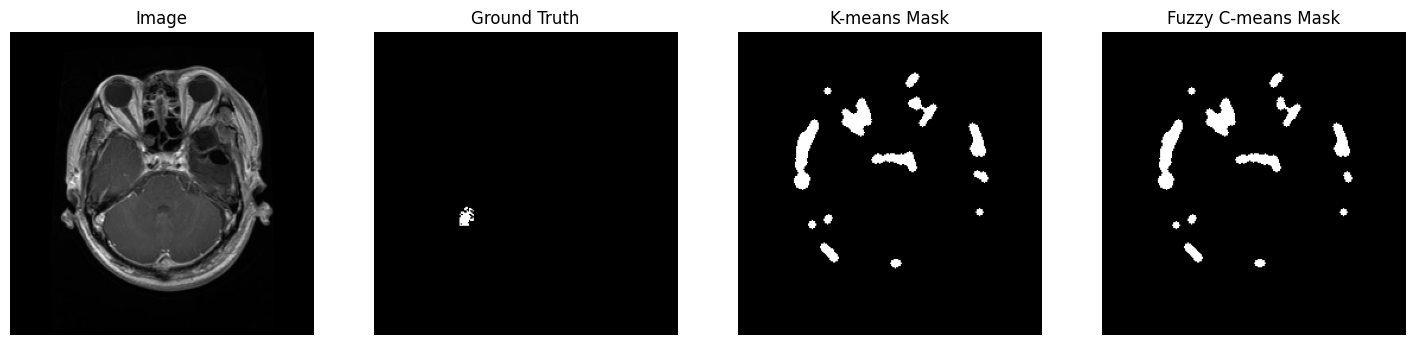

In [ ]:
#Visualize the effect of K-means mask and Fuzzy-C mask on one image

idx = 10  # choose any index < len(X_test)

img = X_test[idx]       # shape (H, W), values 0–1
gt  = Y_test[idx]       # shape (H, W), 0/1

# Run K-means and FCM
k_mask   = kmeans_segmentation(img)         # your existing function
fcm_mask = fcm_segmentation(img)

# Compute Dice scores
dice_k   = dice_score(gt, k_mask)
dice_fcm = dice_score(gt, fcm_mask)

print("Image index:", idx)
print("K-means Dice:", dice_k)
print("FCM Dice    :", dice_fcm)

# Visualize
plt.figure(figsize=(18,4))
plt.subplot(1,4,1); plt.imshow(img, cmap='gray');        plt.title("Image");            plt.axis("off")
plt.subplot(1,4,2); plt.imshow(gt, cmap='gray');         plt.title("Ground Truth");     plt.axis("off")
plt.subplot(1,4,3); plt.imshow(k_mask, cmap='gray');     plt.title("K-means Mask");     plt.axis("off")
plt.subplot(1,4,4); plt.imshow(fcm_mask, cmap='gray');   plt.title("Fuzzy C-means Mask"); plt.axis("off")
plt.show()


In [ ]:
#Evaluate K-means and FCM on 50-images to see the results

import numpy as np

n_samples = min(50, len(X_test))
dice_scores_k   = []
dice_scores_fcm = []

for i in range(n_samples):
    img = X_test[i]
    gt  = Y_test[i]

    k_mask   = kmeans_segmentation(img)
    fcm_mask = fcm_segmentation(img)

    d_k   = dice_score(gt, k_mask)
    d_fcm = dice_score(gt, fcm_mask)

    dice_scores_k.append(d_k)
    dice_scores_fcm.append(d_fcm)

    # Optional: print per-image scores
    # print(f"Image {i}: K-means Dice={d_k:.4f}, FCM Dice={d_fcm:.4f}")

print("\n=== Pipeline 2: 50-image evaluation ===")
print("K-means: Average Dice:", np.mean(dice_scores_k),
      " Min:", np.min(dice_scores_k), " Max:", np.max(dice_scores_k))

print("FCM    : Average Dice:", np.mean(dice_scores_fcm),
      " Min:", np.min(dice_scores_fcm), " Max:", np.max(dice_scores_fcm))



=== Pipeline 2: 50-image evaluation ===
K-means: Average Dice: 0.04645180870464001  Min: 0.0  Max: 0.3150231634658172
FCM    : Average Dice: 0.046726879538370444  Min: 0.0  Max: 0.3150231634658172


In [ ]:


#Pipeline 3 MRF/ICM image segmentation

import numpy as np
from scipy.ndimage import convolve

# 4-neighborhood kernel
NEIGH_KERNEL = np.array([[0, 1, 0],
                         [1, 0, 1],
                         [0, 1, 0]], dtype=np.float32)

def mrf_segmentation(image,
                     n_iter=5,
                     beta=1.2):
    """
    image: 2D array, values 0–1 (float)
    returns: 2D binary mask (0/1) after MRF + ICM
    """

    img = image.astype(np.float32)
    h, w = img.shape

    # ---- 1. Estimate simple intensity models for background / tumor ----
    # Use percentiles to be robust
    bg_mean = np.percentile(img, 40)
    tm_mean = np.percentile(img, 99)   # tumor = very bright tail

    # Variances (avoid 0)
    bg_var = max(1e-4, np.var(img[img < bg_mean + 0.02]))
    tm_var = max(1e-4, np.var(img[img > tm_mean - 0.02]))

    # Gaussian negative log-likelihoods (unary terms)
    # E_data(label=0) = NLL under background model
    # E_data(label=1) = NLL under tumor model
    def nll_gauss(x, mean, var):
        return 0.5 * np.log(2*np.pi*var) + 0.5 * ((x - mean)**2 / var)

    E_bg = nll_gauss(img, bg_mean, bg_var)
    E_tm = nll_gauss(img, tm_mean, tm_var)

    # ---- 2. Initialize labels from pure intensity (no MRF yet) ----
    labels = (E_tm < E_bg).astype(np.int8)   # 1 = tumor, 0 = background

    # ---- 3. ICM iterations ----
    for it in range(n_iter):
        # count neighbors that are tumor
        neigh_tumor = convolve(labels.astype(np.float32),
                               NEIGH_KERNEL, mode='constant', cval=0)

        # pairwise energy: Potts model
        # penalty when label differs from neighbors
        # favor agreement with neighbors
        pair_bg = beta * neigh_tumor            # if we set label=0, neighbors=1 cost
        pair_tm = beta * (4 - neigh_tumor)      # if label=1, neighbors=0 cost

        # total energy for each label
        E0 = E_bg + pair_bg
        E1 = E_tm + pair_tm

        new_labels = (E1 < E0).astype(np.int8)

        # stop early if converged
        if np.array_equal(new_labels, labels):
            break

        labels = new_labels
        print(f"ICM iteration {it+1}/{n_iter} done.")

    mask = labels.astype(np.uint8)
    return mask


ICM iteration 1/5 done.
ICM iteration 2/5 done.
ICM iteration 3/5 done.
ICM iteration 4/5 done.
ICM iteration 5/5 done.
MRF Dice for image 10 : 0.008942247981780607


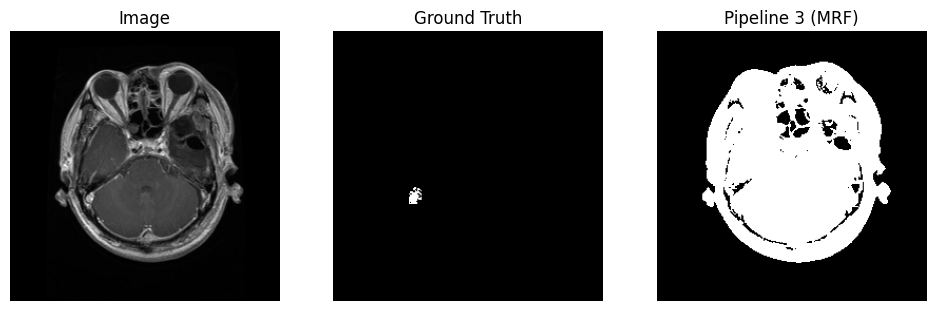

In [ ]:
#Test pipeline 3 on one image to visualize the results

idx = 10  # choose any index < len(X_test)

img = X_test[idx]       # (H, W), 0–1
gt  = Y_test[idx]       # (H, W), 0/1

mrf_mask = mrf_segmentation(img, n_iter=5, beta=1.2)

d_mrf = dice_score(gt, mrf_mask)
print("MRF Dice for image", idx, ":", d_mrf)

plt.figure(figsize=(16,4))
plt.subplot(1,4,1); plt.imshow(img, cmap="gray");      plt.title("Image");     plt.axis("off")
plt.subplot(1,4,2); plt.imshow(gt, cmap="gray");       plt.title("Ground Truth"); plt.axis("off")
plt.subplot(1,4,3); plt.imshow(mrf_mask, cmap="gray"); plt.title("Pipeline 3 (MRF)"); plt.axis("off")

# Optional: compare to K-means mask if you want
# k_mask = kmeans_segmentation(img)
# plt.subplot(1,4,4); plt.imshow(k_mask, cmap="gray"); plt.title("K-means"); plt.axis("off")

plt.show()


In [ ]:
#Image evaluation on 50 images to visualie the result

n_samples = min(50, len(X_test))   # change to 50 if runtime ok
dice_scores_mrf = []

for i in range(n_samples):
    img = X_test[i]
    gt  = Y_test[i]

    mrf_mask = mrf_segmentation(img, n_iter=5, beta=1.2)
    d = dice_score(gt, mrf_mask)
    dice_scores_mrf.append(d)

    print(f"Image {i}: Dice = {d:.4f}")

print("\n=== Pipeline 3: MRF multi-image evaluation ===")
print("MRF: Average Dice:", np.mean(dice_scores_mrf),
      " Min:", np.min(dice_scores_mrf),
      " Max:", np.max(dice_scores_mrf))


ICM iteration 1/5 done.
ICM iteration 2/5 done.
ICM iteration 3/5 done.
ICM iteration 4/5 done.
ICM iteration 5/5 done.
Image 0: Dice = 0.0286
ICM iteration 1/5 done.
ICM iteration 2/5 done.
ICM iteration 3/5 done.
ICM iteration 4/5 done.
ICM iteration 5/5 done.
Image 1: Dice = 0.0461
ICM iteration 1/5 done.
ICM iteration 2/5 done.
Image 2: Dice = 0.1440
ICM iteration 1/5 done.
ICM iteration 2/5 done.
Image 3: Dice = 0.0972
ICM iteration 1/5 done.
ICM iteration 2/5 done.
ICM iteration 3/5 done.
ICM iteration 4/5 done.
ICM iteration 5/5 done.
Image 4: Dice = 0.0311
ICM iteration 1/5 done.
ICM iteration 2/5 done.
Image 5: Dice = 0.1267
ICM iteration 1/5 done.
Image 6: Dice = 0.0195
ICM iteration 1/5 done.
ICM iteration 2/5 done.
Image 7: Dice = 0.0436
ICM iteration 1/5 done.
Image 8: Dice = 0.1755
ICM iteration 1/5 done.
ICM iteration 2/5 done.
Image 9: Dice = 0.0204
ICM iteration 1/5 done.
ICM iteration 2/5 done.
ICM iteration 3/5 done.
ICM iteration 4/5 done.
ICM iteration 5/5 done.
Im

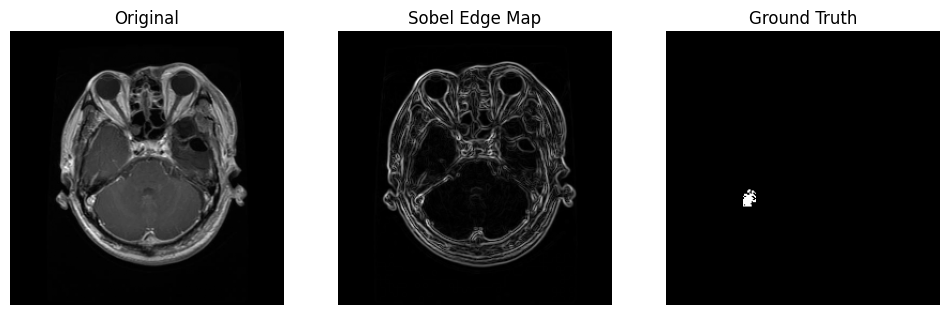

In [ ]:
#Performed Sobel edge detection to see the outcome
import cv2
import numpy as np
import matplotlib.pyplot as plt

idx = 10  # choose any test image
img = X_test[idx]  # shape: (256,256)

# Sobel edges
sobelx = cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=3)
sobely = cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=3)
sobel_edges = np.sqrt(sobelx**2 + sobely**2)
sobel_edges = (sobel_edges / sobel_edges.max()).astype("float32")

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img, cmap="gray");         plt.title("Original"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(sobel_edges, cmap="gray"); plt.title("Sobel Edge Map"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(Y_test[idx], cmap="gray"); plt.title("Ground Truth"); plt.axis("off")
plt.show()


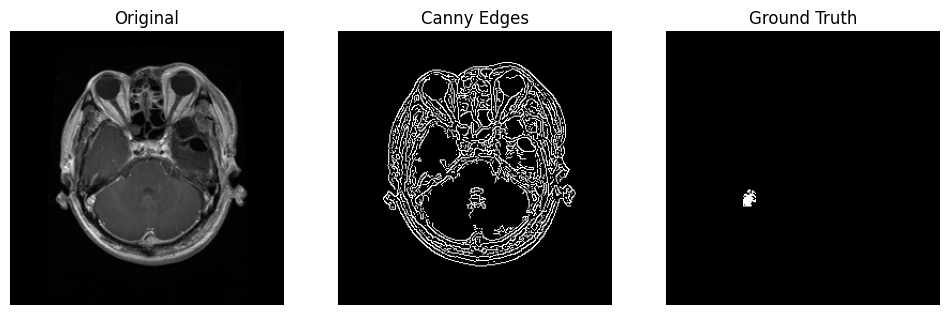

In [ ]:
# Canny edge detection (thresholds may need tuning)
canny = cv2.Canny((img * 255).astype(np.uint8), 20, 80)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(img, cmap="gray");         plt.title("Original"); plt.axis("off")
plt.subplot(1,3,2); plt.imshow(canny, cmap="gray");       plt.title("Canny Edges"); plt.axis("off")
plt.subplot(1,3,3); plt.imshow(Y_test[idx], cmap="gray"); plt.title("Ground Truth"); plt.axis("off")
plt.show()


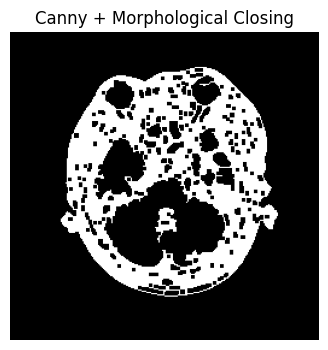

In [ ]:
#Canny and Morphological Closing
#Visualize it

kernel = np.ones((3,3), np.uint8)
canny_clean = cv2.morphologyEx(canny, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(10,4))
plt.imshow(canny_clean, cmap="gray")
plt.title("Canny + Morphological Closing")
plt.axis("off")
plt.show()
